# Лабораторна робота 4. Advanced Net

**Маврикін Едуард, ФБ-62мп**

Мета: опанувати принципи побудови та навчання трансформерних моделей для машинного перекладу; набути навичок використання готових моделей Hugging Face для роботи з текстами й зображеннями.

План:
1. Трансформер encoder–decoder з нуля для перекладу англійська → українська (датасет Tatoeba з manythings.org/anki).
2. Моделі Hugging Face: (а) pipeline для zero-shot classification, summarization, translation українською; (б) fine-tuning DistilRoBERTa на датасеті AG News з лабораторної 2 і порівняння з TF-IDF + NB / LR.
3. Зображення: (а) Text-to-Image через Diffusers; (б) ознаки DINOv2 для 10 знімків EuroSAT і попарні відстані.

In [1]:
import os, re, math, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import Counter

warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(dev, torch.cuda.get_device_name(0) if dev.type == 'cuda' else '')

cuda NVIDIA GeForce RTX 4080 Laptop GPU


## 1. Машинний переклад: трансформер з нуля

### 1.1. Дані

Файл `ukr.txt` з manythings.org/anki: пари речень англійською та українською з проєкту Tatoeba. Беру речення до 15 токенів, переводжу в нижній регістр і токенізую простим регулярним виразом: слова (разом з апострофом) і знаки пунктуації окремо.

In [2]:
def tokenize(s):
    s = s.lower().replace('’', "'").replace('ʼ', "'")
    return re.findall(r"[\w']+|[^\w\s]", s)

pairs = []
for line in open('data/ukr.txt', encoding='utf-8'):
    p = line.rstrip('\n').split('\t')
    if len(p) >= 2:
        en, uk = tokenize(p[0]), tokenize(p[1])
        if 0 < len(en) <= 15 and 0 < len(uk) <= 15:
            pairs.append((en, uk))
print('пар усього:', len(pairs))
random.shuffle(pairs)
test_pairs, val_pairs, train_pairs = pairs[:2000], pairs[2000:4000], pairs[4000:]
print('train / val / test:', len(train_pairs), len(val_pairs), len(test_pairs))
for en, uk in train_pairs[:5]:
    print(' '.join(en), ' -> ', ' '.join(uk))

пар усього: 159566
train / val / test: 155566 2000 2000
i saw a snake .  ->  я бачив змію .
tom isn't as intelligent as you .  ->  том не такий розумний , як ти .
please give me this pen .  ->  дай мені цю ручку , будь ласка .
where's the boss ?  ->  де шеф ?
neither tom nor mary can speak french .  ->  ані том , ані мері , не говорять французькою .


In [3]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3

class Vocab:
    def __init__(self, sents, min_freq=2):
        cnt = Counter(t for s in sents for t in s)
        self.itos = ['<pad>', '<sos>', '<eos>', '<unk>'] + sorted(t for t, c in cnt.items() if c >= min_freq)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
    def encode(self, toks): return [self.stoi.get(t, UNK) for t in toks]
    def decode(self, ids): return [self.itos[i] for i in ids]
    def __len__(self): return len(self.itos)

src_vocab = Vocab([en for en, _ in train_pairs])
tgt_vocab = Vocab([uk for _, uk in train_pairs])
print('словник EN:', len(src_vocab), ' словник UK:', len(tgt_vocab))
lens = [len(uk) for _, uk in train_pairs]
print('середня довжина UK-речення:', round(np.mean(lens), 1))

def make_batch(batch):
    src = [torch.tensor(src_vocab.encode(en) + [EOS]) for en, _ in batch]
    tgt = [torch.tensor([SOS] + tgt_vocab.encode(uk) + [EOS]) for _, uk in batch]
    src = nn.utils.rnn.pad_sequence(src, batch_first=True, padding_value=PAD)
    tgt = nn.utils.rnn.pad_sequence(tgt, batch_first=True, padding_value=PAD)
    return src, tgt

train_dl = torch.utils.data.DataLoader(train_pairs, batch_size=128, shuffle=True, collate_fn=make_batch)
val_dl = torch.utils.data.DataLoader(val_pairs, batch_size=256, collate_fn=make_batch)

словник EN: 7639  словник UK: 17927
середня довжина UK-речення: 6.1


### 1.2. Архітектура

Реалізую всі блоки трансформера самостійно (з PyTorch беру лише `nn.Linear`, `nn.Embedding`, `nn.LayerNorm`, `nn.Dropout`):

- **Scaled dot-product attention:** `softmax(QKᵀ / √d_k) · V`;
- **Multi-head attention:** `h` голів зі своїми проєкціями Q, K, V, результати конкатенуються;
- **Позиційне кодування:** синусоїди різних частот, бо attention сам по собі не знає порядку слів;
- **Encoder layer:** self-attention + feed-forward, кожен з residual-звʼязком і LayerNorm (pre-norm, так навчання стабільніше);
- **Decoder layer:** masked self-attention (декодер не бачить майбутніх слів) + cross-attention на виходи енкодера + feed-forward.

In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.w_q, self.w_k, self.w_v = (nn.Linear(d_model, d_model) for _ in range(3))
        self.w_o = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)
        self.attn = None                                    # збережу ваги уваги для візуалізації

    def forward(self, q, k, v, mask=None):
        B, Tq, Tk = q.size(0), q.size(1), k.size(1)
        Q = self.w_q(q).view(B, Tq, self.h, self.d_k).transpose(1, 2)   # (B, h, Tq, d_k)
        K = self.w_k(k).view(B, Tk, self.h, self.d_k).transpose(1, 2)
        V = self.w_v(v).view(B, Tk, self.h, self.d_k).transpose(1, 2)
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.d_k)          # (B, h, Tq, Tk)
        if mask is not None:
            scores = scores.masked_fill(~mask, float('-inf'))
        attn = scores.softmax(dim=-1)
        self.attn = attn.detach()
        out = (self.drop(attn) @ V).transpose(1, 2).reshape(B, Tq, -1)
        return self.w_o(out)


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
    def forward(self, x): return self.net(x)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=64):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]


class EncoderLayer(nn.Module):
    def __init__(self, d, h, d_ff, p):
        super().__init__()
        self.self_attn, self.ff = MultiHeadAttention(d, h, p), FeedForward(d, d_ff, p)
        self.n1, self.n2, self.drop = nn.LayerNorm(d), nn.LayerNorm(d), nn.Dropout(p)
    def forward(self, x, src_mask):
        y = self.n1(x)
        x = x + self.drop(self.self_attn(y, y, y, src_mask))
        return x + self.drop(self.ff(self.n2(x)))


class DecoderLayer(nn.Module):
    def __init__(self, d, h, d_ff, p):
        super().__init__()
        self.self_attn, self.cross_attn = MultiHeadAttention(d, h, p), MultiHeadAttention(d, h, p)
        self.ff = FeedForward(d, d_ff, p)
        self.n1, self.n2, self.n3, self.drop = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d), nn.Dropout(p)
    def forward(self, x, memory, src_mask, tgt_mask):
        y = self.n1(x)
        x = x + self.drop(self.self_attn(y, y, y, tgt_mask))
        x = x + self.drop(self.cross_attn(self.n2(x), memory, memory, src_mask))
        return x + self.drop(self.ff(self.n3(x)))


class Transformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d=256, h=8, n_layers=3, d_ff=1024, p=0.1):
        super().__init__()
        self.d = d
        self.src_emb, self.tgt_emb = nn.Embedding(src_vocab, d, padding_idx=PAD), nn.Embedding(tgt_vocab, d, padding_idx=PAD)
        self.pos, self.drop = PositionalEncoding(d), nn.Dropout(p)
        self.enc = nn.ModuleList(EncoderLayer(d, h, d_ff, p) for _ in range(n_layers))
        self.dec = nn.ModuleList(DecoderLayer(d, h, d_ff, p) for _ in range(n_layers))
        self.enc_norm, self.dec_norm = nn.LayerNorm(d), nn.LayerNorm(d)
        self.out = nn.Linear(d, tgt_vocab)

    @staticmethod
    def src_mask(src):                                      # (B, 1, 1, Ts): не дивитись на <pad>
        return (src != PAD)[:, None, None, :]

    @staticmethod
    def tgt_mask(tgt):                                      # (B, 1, Tt, Tt): <pad> + causal mask
        T = tgt.size(1)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt.device))
        return (tgt != PAD)[:, None, None, :] & causal

    def encode(self, src):
        m = self.src_mask(src)
        x = self.drop(self.pos(self.src_emb(src) * math.sqrt(self.d)))
        for layer in self.enc:
            x = layer(x, m)
        return self.enc_norm(x), m

    def decode(self, tgt, memory, src_mask):
        x = self.drop(self.pos(self.tgt_emb(tgt) * math.sqrt(self.d)))
        tm = self.tgt_mask(tgt)
        for layer in self.dec:
            x = layer(x, memory, src_mask, tm)
        return self.out(self.dec_norm(x))

    def forward(self, src, tgt_in):
        memory, sm = self.encode(src)
        return self.decode(tgt_in, memory, sm)


model = Transformer(len(src_vocab), len(tgt_vocab)).to(dev)
for p_ in model.parameters():
    if p_.dim() > 1:
        nn.init.xavier_uniform_(p_)
print('параметрів:', f'{sum(p.numel() for p in model.parameters()):,}')

параметрів: 16,682,759


### 1.3. Навчання

Функція втрат: крос-ентропія з label smoothing 0.1 (паддінг ігнорується). Оптимізатор Adam (β₂ = 0.98) з розкладом learning rate з оригінальної статті «Attention Is All You Need»: лінійне зростання протягом warmup-кроків, потім спад як 1/√step.

In [5]:
EPOCHS, WARMUP = 15, 2000
opt = torch.optim.Adam(model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 256 ** -0.5 * min((s + 1) ** -0.5, (s + 1) * WARMUP ** -1.5))
crit = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)

def run_epoch(dl, train):
    model.train(train)
    tot, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for src, tgt in dl:
            src, tgt = src.to(dev), tgt.to(dev)
            with torch.autocast('cuda', dtype=torch.bfloat16):
                logits = model(src, tgt[:, :-1])
                loss = crit(logits.float().reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step(); sched.step()
            tot += loss.item() * src.size(0); n += src.size(0)
    return tot / n

hist = {'train': [], 'val': []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr, va = run_epoch(train_dl, True), run_epoch(val_dl, False)
    hist['train'].append(tr); hist['val'].append(va)
    print(f'епоха {ep:2d}: train loss {tr:.3f}  val loss {va:.3f}  ({time.time() - t0:.0f} с)')

епоха  1: train loss 4.921  val loss 3.157  (39 с)


епоха  2: train loss 2.955  val loss 2.602  (78 с)


епоха  3: train loss 2.569  val loss 2.415  (119 с)


епоха  4: train loss 2.387  val loss 2.338  (158 с)


епоха  5: train loss 2.280  val loss 2.266  (198 с)


епоха  6: train loss 2.207  val loss 2.230  (238 с)


... (5 outputs left out)

епоха 12: train loss 2.009  val loss 2.170  (478 с)


епоха 13: train loss 1.992  val loss 2.158  (518 с)


епоха 14: train loss 1.977  val loss 2.157  (558 с)


епоха 15: train loss 1.965  val loss 2.160  (598 с)


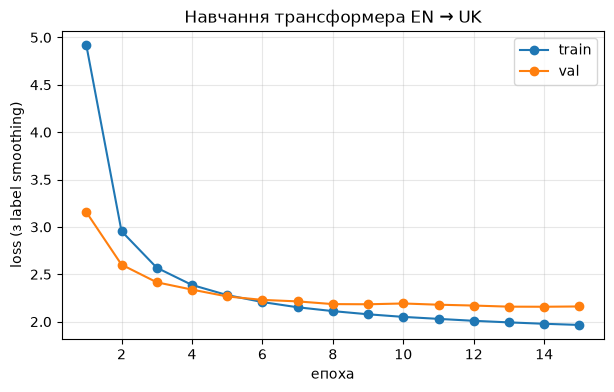

In [6]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), hist['train'], 'o-', label='train')
plt.plot(range(1, EPOCHS + 1), hist['val'], 'o-', label='val')
plt.xlabel('епоха'); plt.ylabel('loss (з label smoothing)'); plt.title('Навчання трансформера EN → UK')
plt.grid(alpha=.3); plt.legend(); plt.show()

### 1.4. Переклад і оцінка якості

Переклад жадібним декодуванням: декодер починає з `<sos>` і на кожному кроці бере найімовірніше слово, доки не згенерує `<eos>`. Якість на тестовій вибірці (2000 речень, які модель не бачила) оцінюю метрикою BLEU (sacrebleu, по токенах).

In [7]:
import sacrebleu

@torch.no_grad()
def translate(sentences, max_len=25):
    model.eval()
    toks = [tokenize(s) if isinstance(s, str) else s for s in sentences]
    src, _ = make_batch([(t, []) for t in toks])
    src = src.to(dev)
    memory, sm = model.encode(src)
    ys = torch.full((src.size(0), 1), SOS, device=dev)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=dev)
    for _ in range(max_len):
        nxt = model.decode(ys, memory, sm)[:, -1].argmax(-1)
        ys = torch.cat([ys, nxt[:, None]], 1)
        done |= nxt == EOS
        if done.all():
            break
    res = []
    for row in ys[:, 1:].tolist():
        row = row[:row.index(EOS)] if EOS in row else row
        res.append(' '.join(tgt_vocab.decode(row)))
    return res

hyps, refs = [], []
for i in range(0, len(test_pairs), 250):
    chunk = test_pairs[i:i + 250]
    hyps += translate([en for en, _ in chunk])
    refs += [' '.join(uk) for _, uk in chunk]
bleu = sacrebleu.corpus_bleu(hyps, [refs], tokenize='none')
print(f'BLEU на тесті: {bleu.score:.1f}')
for (en, uk), h in list(zip(test_pairs, hyps))[:12]:
    print(f'EN : {" ".join(en)}\nREF: {" ".join(uk)}\nOUT: {h}\n')

BLEU на тесті: 46.2
EN : i work fast .
REF: я працюю швидко .
OUT: я швидко працюю .

EN : is this translation correct ?
REF: це правильний переклад ?
OUT: це і є переклад ?

EN : there are no pyramids in europe .
REF: в європі немає пірамід .
OUT: у європі немає <unk> .

EN : you've told me that before .
REF: ти мені вже казала це раніше .
OUT: ти сказав мені це раніше .

EN : tom will leave boston next month .
REF: том поїде з бостона наступного місяця .
OUT: том поїде з бостона наступного місяця .

EN : let's celebrate .
REF: давайте відсвяткуємо .
OUT: давайте святкувати .

EN : the water's clean .
REF: вода чиста .
OUT: вода чиста .

EN : i have a solution .
REF: у мене є рішення .
OUT: я маю рішення .

EN : it's 2 : 30 now .
REF: зараз 2 : 30 .
OUT: зараз пів на третю .

EN : i will start after he comes .
REF: я почну , коли він прийде .
OUT: я почну після того , як він прийде .

EN : i don't like poker at all .
REF: покер мені взагалі не подобається .
OUT: я взагалі не люблю пок

In [8]:
my_sentences = ['I love my university.', 'Where is the nearest train station?', 'The weather is beautiful today.',
                'My brother works as a programmer.', 'Can you help me with this task?',
                'We will go to the sea next summer.', 'This book is more interesting than the film.']
for s, t in zip(my_sentences, translate(my_sentences)):
    print(f'{s:45s} -> {t}')

I love my university.                         -> я обожнюю своє університет .
Where is the nearest train station?           -> де знаходиться найближчий вокзал ?
The weather is beautiful today.               -> сьогодні гарна погода .
My brother works as a programmer.             -> мій брат працює <unk> .
Can you help me with this task?               -> можеш допомогти мені з цим вирішити цю проблему ?
We will go to the sea next summer.            -> наступного літа ми підемо до моря .
This book is more interesting than the film.  -> ця книжка цікавіша від фільму .


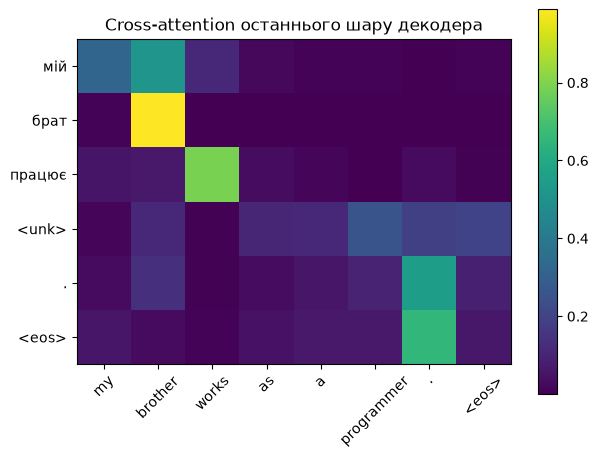

In [9]:
s = 'my brother works as a programmer .'
translate([s])
tr_toks = translate([s])[0].split()
attn = model.dec[-1].cross_attn.attn[0].float().mean(0).cpu().numpy()     # середнє по головах
src_t = tokenize(s) + ['<eos>']
plt.figure(figsize=(7, 5))
plt.imshow(attn[:len(tr_toks) + 1, :len(src_t)], cmap='viridis')
plt.xticks(range(len(src_t)), src_t, rotation=45); plt.yticks(range(len(tr_toks) + 1), tr_toks + ['<eos>'])
plt.title('Cross-attention останнього шару декодера'); plt.colorbar(); plt.show()

**Результати перекладу.** Модель з 16.7 млн параметрів навчалась 15 епох (~10 хв на GPU). Val loss перестав помітно падати після 8-9 епохи (2.18 → 2.16), перенавчання немає: train і val loss близькі. BLEU на тесті **46.2**. Для коротких речень Tatoeba це добрий результат: значна частина перекладів збігається з еталоном дослівно (`том поїде з бостона наступного місяця .`), а багато «помилок» насправді є правильними перекладами іншими словами (`я маю рішення` замість `у мене є рішення`, `я взагалі не люблю покер`). BLEU рахує лише збіг слів, тому такі варіанти занижують оцінку.

Основні проблеми:
- **рідкісні слова** → `<unk>` (`programmer`, `pyramids`, `gold`): словник побудований на цілих словах з частотою ≥ 2, а в українській через відмінки одне слово має багато форм. Це вирішує субсловна токенізація (BPE, SentencePiece);
- **узгодження роду** (`своє університет`) і зайві повтори в довших реченнях (`з цим вирішити цю проблему`): модель маленька і бачила лише короткі побутові фрази.

**Cross-attention** показує, що модель сама навчилась вирівнювати слова: `брат` дивиться на `brother` (вага ≈ 0.95), `працює` на `works`, а `<unk>` на `programmer`. Для `мій` увага розподілена між `my` і `brother`, бо форма займенника залежить від роду іменника.

## 2. Текстові моделі Hugging Face

### 2.а) Pipeline для української мови

Моделі:
- zero-shot classification: `MoritzLaurer/mDeBERTa-v3-base-mnli-xnli`, багатомовна mDeBERTa, донавчена на NLI (зокрема XNLI). Zero-shot класифікація зводиться до питання «чи випливає з тексту гіпотеза "Цей текст про {мітку}"»;
- summarization: `csebuetnlp/mT5_multilingual_XLSum`, mT5, навчена на новинах BBC 45 мовами, серед яких українська;
- translation: `Helsinki-NLP/opus-mt-uk-en` та `Helsinki-NLP/opus-mt-en-uk` (MarianMT, навчені на корпусі OPUS).

In [10]:
from transformers import pipeline

zsc = pipeline('zero-shot-classification', model='MoritzLaurer/mDeBERTa-v3-base-mnli-xnli', device=0)
text = ('Збірна України з футболу здобула впевнену перемогу над командою Ісландії і вийшла до фінальної '
        'частини чемпіонату Європи. Вирішальний гол забив Михайло Мудрик.')
labels = ['спорт', 'політика', 'технології', 'економіка', 'культура']
r = zsc(text, candidate_labels=labels, hypothesis_template='Цей текст про {}.')
for l, s in zip(r['labels'], r['scores']):
    print(f'{l:12s} {s:.3f}')

спорт        0.987
культура     0.006
економіка    0.003
політика     0.002
технології   0.002


In [11]:
summ = pipeline('summarization', model='csebuetnlp/mT5_multilingual_XLSum', device=0)
article = ('Київський політехнічний інститут імені Ігоря Сікорського відкрив нову лабораторію кібербезпеки. '
           'У лабораторії студенти зможуть досліджувати захист промислових систем керування, аналізувати '
           'шкідливе програмне забезпечення та відпрацьовувати реагування на кіберінциденти. Обладнання для '
           'лабораторії передали міжнародні партнери університету. За словами ректора, найближчим часом '
           'на базі лабораторії почнуть проводити змагання з кібербезпеки для студентів з усієї України.')
out = summ(article, max_length=60, num_beams=4, no_repeat_ngram_size=2)
print('Текст:', len(article.split()), 'слів')
print('Резюме:', out[0]['summary_text'])

Текст: 53 слів
Резюме: У Києві відкрили нову лабораторію кібербезпеки.


In [12]:
uk_en = pipeline('translation', model='Helsinki-NLP/opus-mt-uk-en', device=0)
en_uk = pipeline('translation', model='Helsinki-NLP/opus-mt-en-uk', device=0)
print(uk_en('Штучний інтелект змінює спосіб, у який ми навчаємося та працюємо.')[0]['translation_text'])
print(en_uk('Artificial intelligence is changing the way we learn and work.')[0]['translation_text'])

The artificial intelligence changes the way we learn and work.
Штучний інтелект змінює наш спосіб навчання і роботи.


Для порівняння прогоню готову модель opus-mt-en-uk на тих самих 500 тестових реченнях, що й мій трансформер, і порахую BLEU однаково (нижній регістр, та сама токенізація).

In [13]:
sub = test_pairs[:500]
opus_hyp = [' '.join(tokenize(o['translation_text'])) for o in en_uk([' '.join(en) for en, _ in sub], batch_size=64)]
refs_sub = [' '.join(uk) for _, uk in sub]
print(f'BLEU, мій трансформер: {sacrebleu.corpus_bleu(hyps[:500], [refs_sub], tokenize="none").score:.1f}')
print(f'BLEU, opus-mt-en-uk:   {sacrebleu.corpus_bleu(opus_hyp, [refs_sub], tokenize="none").score:.1f}')
for i in range(5):
    print(f'EN  : {" ".join(sub[i][0])}\nREF : {refs_sub[i]}\nMY  : {hyps[i]}\nOPUS: {opus_hyp[i]}\n')

BLEU, мій трансформер: 47.4
BLEU, opus-mt-en-uk:   46.1
EN  : i work fast .
REF : я працюю швидко .
MY  : я швидко працюю .
OPUS: я працюю швидко .

EN  : is this translation correct ?
REF : це правильний переклад ?
MY  : це і є переклад ?
OPUS: цей переклад правильний ?

EN  : there are no pyramids in europe .
REF : в європі немає пірамід .
MY  : у європі немає <unk> .
OPUS: на європе немає пірамід .

EN  : you've told me that before .
REF : ти мені вже казала це раніше .
MY  : ти сказав мені це раніше .
OPUS: ти мені це вже казав .

EN  : tom will leave boston next month .
REF : том поїде з бостона наступного місяця .
MY  : том поїде з бостона наступного місяця .
OPUS: том уедет из бостона в следующем месяце .



- **Zero-shot:** mDeBERTa правильно віднесла новину до класу «спорт» з імовірністю 0.987, хоча ніколи не вчилась на цих мітках. Мітки задаються просто словами, тому класифікатор можна змінювати без донавчання.
- **Summarization:** mT5 XLSum стиснула 53 слова до одного змістовного речення `У Києві відкрили нову лабораторію кібербезпеки.` Модель не копіює речення з тексту, а генерує нове (абстрактивне резюме). Щоправда, вона дописала «У Києві», хоча в тексті прямо цього немає (лише «Київський політехнічний інститут»).
- **Translation:** обидва напрямки opus-mt перекладають природно.

**Порівняння з моїм трансформером** на тих самих 500 тестових реченнях: мій 47.4 BLEU, opus-mt-en-uk 46.1. Мій результат вищий не тому, що модель краща (opus-mt значно більша і навчена на мільйонах речень), а тому, що мій трансформер навчався на даних з того самого джерела (Tatoeba) і переймає їхній стиль, а BLEU рахує збіг з конкретним еталоном. Цікаво, що opus-mt-en-uk іноді видає **російський** текст (`том уедет из бостона в следующем месяце`) або суржик (`на європе`): у корпусі OPUS частина «українських» даних насправді російська. Тобто готова модель знає більше слів, але має проблеми з якістю навчальних даних, а моя модель вузька, але чиста.

### 2.б) Fine-tuning на AG News (датасет з лабораторної 2)

Датасет той самий: 3 класи (World, Sports, Sci/Tech), 30 000 текстів у train і офіційна тестова вибірка 5700 текстів. Текст = заголовок + '. ' + опис, як у лабораторній 2.

Модель: `distilroberta-base` (82 млн параметрів), повне донавчання (full fine-tuning) усіх ваг, 2 епохи. Зверху на токен `<s>` додається лінійний класифікатор на 3 класи.

In [14]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

train_df = pd.read_csv('../lab2/ag_news_3cls_train.csv')
test_df = pd.read_csv('../lab2/ag_news_3cls_test.csv')
for d in (train_df, test_df):
    d['text'] = d['title'] + '. ' + d['description']
classes = sorted(train_df['label'].unique())
c2i = {c: i for i, c in enumerate(classes)}
print(classes, train_df.shape, test_df.shape)

MODEL = 'distilroberta-base'
tok = AutoTokenizer.from_pretrained(MODEL)
clf = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=3).to(dev)

def encode_df(d):
    enc = tok(list(d['text']), truncation=True, max_length=128, padding='max_length', return_tensors='pt')
    return torch.utils.data.TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(d['label'].map(c2i).values))

tr_ds, te_ds = encode_df(train_df), encode_df(test_df)
tr_loader = torch.utils.data.DataLoader(tr_ds, batch_size=32, shuffle=True)
te_loader = torch.utils.data.DataLoader(te_ds, batch_size=128)

['Sci/Tech', 'Sports', 'World'] (30000, 4) (5700, 4)


In [15]:
FT_EPOCHS = 2
opt_ft = torch.optim.AdamW(clf.parameters(), lr=2e-5, weight_decay=0.01)
total = FT_EPOCHS * len(tr_loader)
sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lambda s: min((s + 1) / (0.06 * total), max(0.0, (total - s) / (0.94 * total))))

@torch.no_grad()
def predict(loader):
    clf.eval(); preds = []
    for ids, am, _ in loader:
        with torch.autocast('cuda', dtype=torch.bfloat16):
            preds.append(clf(input_ids=ids.to(dev), attention_mask=am.to(dev)).logits.argmax(-1).cpu())
    return torch.cat(preds).numpy()

y_test = test_df['label'].map(c2i).values
t0 = time.time()
ft_loss = []
for ep in range(FT_EPOCHS):
    clf.train()
    for step, (ids, am, y) in enumerate(tr_loader):
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = clf(input_ids=ids.to(dev), attention_mask=am.to(dev), labels=y.to(dev)).loss
        opt_ft.zero_grad(); loss.backward(); opt_ft.step(); sched_ft.step()
        if step % 50 == 0:
            ft_loss.append(loss.item())
    acc = accuracy_score(y_test, predict(te_loader))
    print(f'епоха {ep + 1}: test accuracy {acc:.4f}  ({time.time() - t0:.0f} с)')

епоха 1: test accuracy 0.9677  (46 с)


епоха 2: test accuracy 0.9746  (91 с)


accuracy = 0.9746
              precision    recall  f1-score   support

    Sci/Tech      0.971     0.971     0.971      1900
      Sports      0.984     0.990     0.987      1900
       World      0.969     0.963     0.966      1900

    accuracy                          0.975      5700
   macro avg      0.975     0.975     0.975      5700
weighted avg      0.975     0.975     0.975      5700



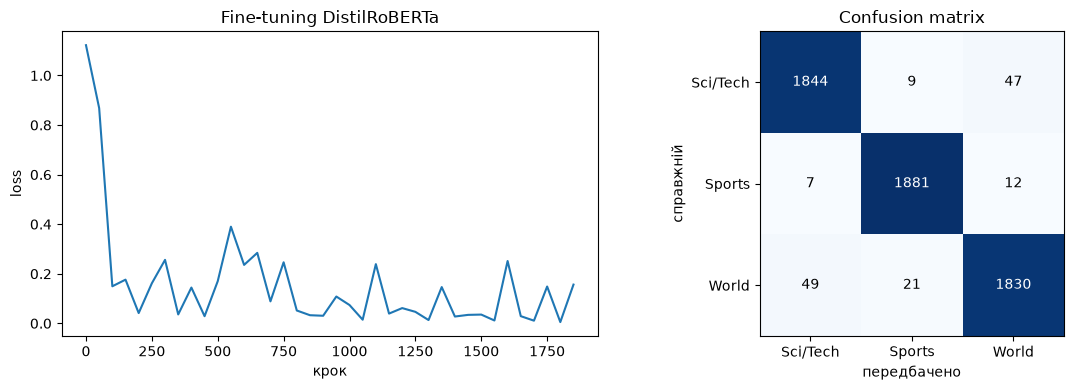

In [16]:
pred_ft = predict(te_loader)
print('accuracy =', round(accuracy_score(y_test, pred_ft), 4))
print(classification_report(y_test, pred_ft, target_names=classes, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(len(ft_loss)) * 50, ft_loss); ax[0].set_xlabel('крок'); ax[0].set_ylabel('loss'); ax[0].set_title('Fine-tuning DistilRoBERTa')
cm = confusion_matrix(y_test, pred_ft)
ax[1].imshow(cm, cmap='Blues')
for i in range(3):
    for j in range(3):
        ax[1].text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(classes); ax[1].set_yticks(range(3)); ax[1].set_yticklabels(classes)
ax[1].set_xlabel('передбачено'); ax[1].set_ylabel('справжній'); ax[1].set_title('Confusion matrix')
plt.tight_layout(); plt.show()

In [17]:
comp = pd.DataFrame({
    'модель': ['TF-IDF + Naive Bayes (лаба 2)', 'TF-IDF + Logistic Regression (лаба 2)', 'LSTM + GloVe (лаба 3)', 'DistilRoBERTa fine-tuning'],
    'accuracy': [0.9554, 0.9504, 0.9560, round(accuracy_score(y_test, pred_ft), 4)],
})
comp

,модель,accuracy
0,TF-IDF + Naive Bayes (лаба 2),0.9554
1,TF-IDF + Logistic Regression (лаба 2),0.9504
2,LSTM + GloVe (лаба 3),0.9560
3,DistilRoBERTa fine-tuning,0.9746


Повне донавчання DistilRoBERTa на 2 епохи (~1.5 хв на GPU) дало **accuracy 0.975** на тій самій тестовій вибірці з 5700 текстів, що в лабораторній 2. Це на 2 п.п. краще за найкращу модель лабораторної 2 (TF-IDF + NB, 0.955) і за LSTM + GloVe з лабораторної 3 (0.956), тобто кількість помилок зменшилась з ~255 до 145 (майже вдвічі). Уже після першої епохи модель мала 0.968.

Макро-F1 0.975: Sports розпізнається майже ідеально (F1 0.987), найбільше плутанини між **World і Sci/Tech** (47 і 49 помилок): це новини про технологічні компанії, уряди і міжнародні угоди, які справді на межі тем.

Чому трансформер кращий: TF-IDF дивиться лише на набір слів, а RoBERTa попередньо навчена на величезному корпусі й розуміє контекст і значення слів у реченні, тому їй вистачає 30 тис. прикладів і 2 епох, щоб перевершити класичні методи. Ціна - 82 млн параметрів і потреба в GPU, тоді як TF-IDF + NB навчається за секунди на CPU.

## 3. Візуальна інформація

### 3.а) Text-to-Image (Diffusers)

Модель `stabilityai/sd-turbo`: дистильована Stable Diffusion 2.1, яка генерує зображення 512×512 за 1–4 кроки денойзингу замість 25–50. Текстовий запит кодується CLIP-енкодером, UNet поступово прибирає шум у латентному просторі, а VAE-декодер перетворює латент на зображення.

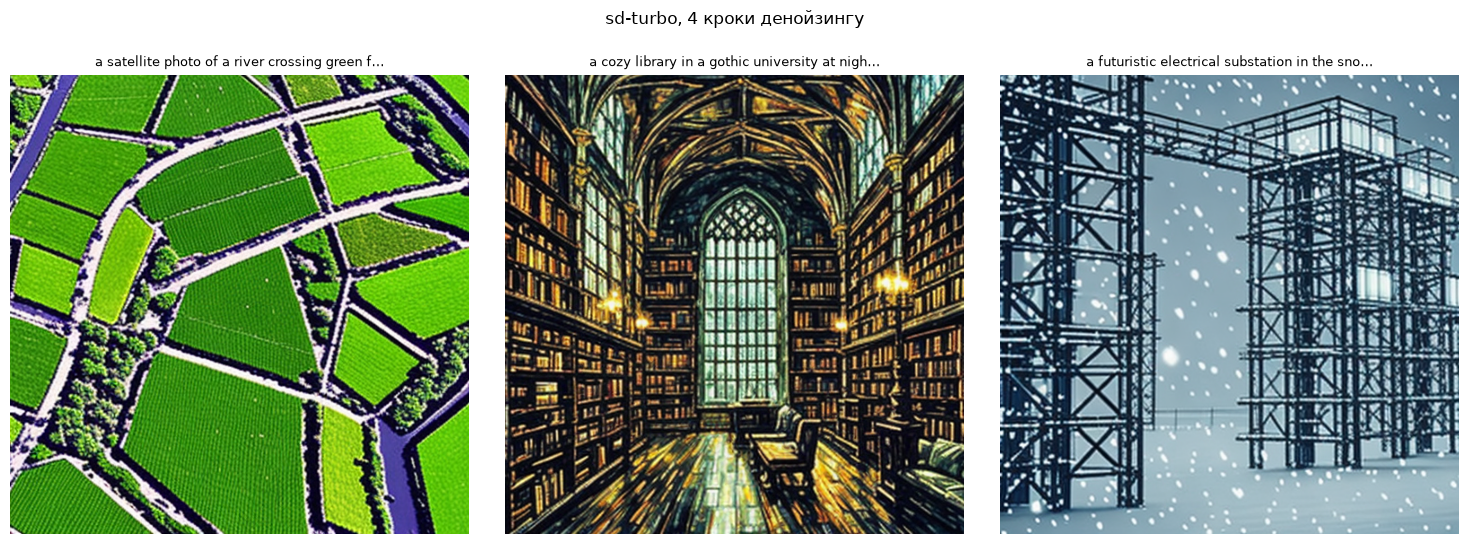

In [18]:
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog
dlog.disable_progress_bar(); dlog.set_verbosity_error()

sd = AutoPipelineForText2Image.from_pretrained('stabilityai/sd-turbo', torch_dtype=torch.float16, variant='fp16').to(dev)
sd.set_progress_bar_config(disable=True)
prompts = ['a satellite photo of a river crossing green farm fields, high detail',
           'a cozy library in a gothic university at night, warm light, oil painting',
           'a futuristic electrical substation in the snow, cinematic lighting']
fig, ax = plt.subplots(1, 3, figsize=(15, 5.5))
for a, pr in zip(ax, prompts):
    g = torch.Generator(dev).manual_seed(7)
    img = sd(pr, num_inference_steps=4, guidance_scale=0.0, generator=g).images[0]
    a.imshow(img); a.axis('off'); a.set_title(pr[:45] + '…', fontsize=9)
plt.suptitle('sd-turbo, 4 кроки денойзингу'); plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

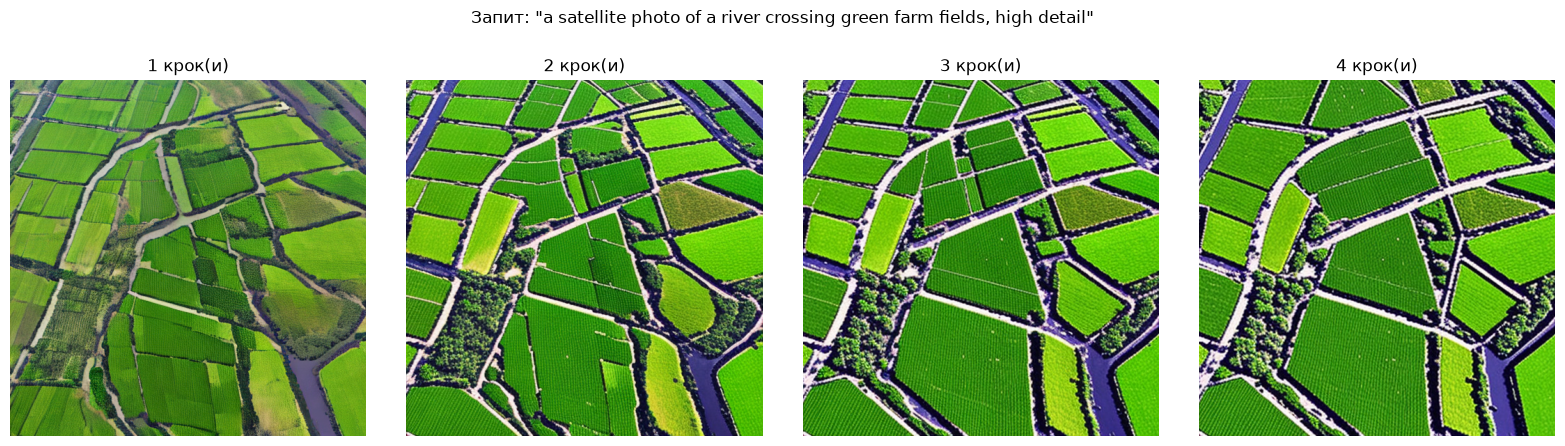

In [19]:
g = torch.Generator(dev).manual_seed(7)
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, steps in zip(ax, (1, 2, 3, 4)):
    g = torch.Generator(dev).manual_seed(7)
    a.imshow(sd(prompts[0], num_inference_steps=steps, guidance_scale=0.0, generator=g).images[0])
    a.set_title(f'{steps} крок(и)'); a.axis('off')
plt.suptitle(f'Запит: "{prompts[0]}"'); plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()
del sd; torch.cuda.empty_cache()

sd-turbo генерує картинку 512×512 за 4 кроки менше ніж за секунду. Усі три зображення відповідають запитам: поля з річкою у вигляді супутникового знімка, готична бібліотека в стилі олійного живопису, металеві конструкції підстанції в снігу. Видно і типові вади: насичені «неприродні» кольори та трохи «мультяшна» річка на першому зображенні.

Порівняння кількості кроків: уже після **1 кроку** є повна композиція (поля, дороги, річка), але картинка розмита. 2-4 кроки додають деталі й контраст, при цьому структура майже не змінюється, бо seed однаковий. Для turbo-моделей більше 4 кроків не дає покращення: модель дистильована саме для генерації за 1-4 кроки, і guidance_scale = 0 (вона навчена без classifier-free guidance).

### 3.б) Ознаки DINOv2 для 10 зображень

Беру 10 знімків EuroSAT (датасет з лабораторної 3), по 2 з 5 класів: Forest, River, Highway, Residential, SeaLake. Модель `facebook/dinov2-small` (ViT-S/14, самонавчання без міток). Вектор ознак зображення: CLS-токен останнього шару (384 числа), після чого виконую L2-нормування.

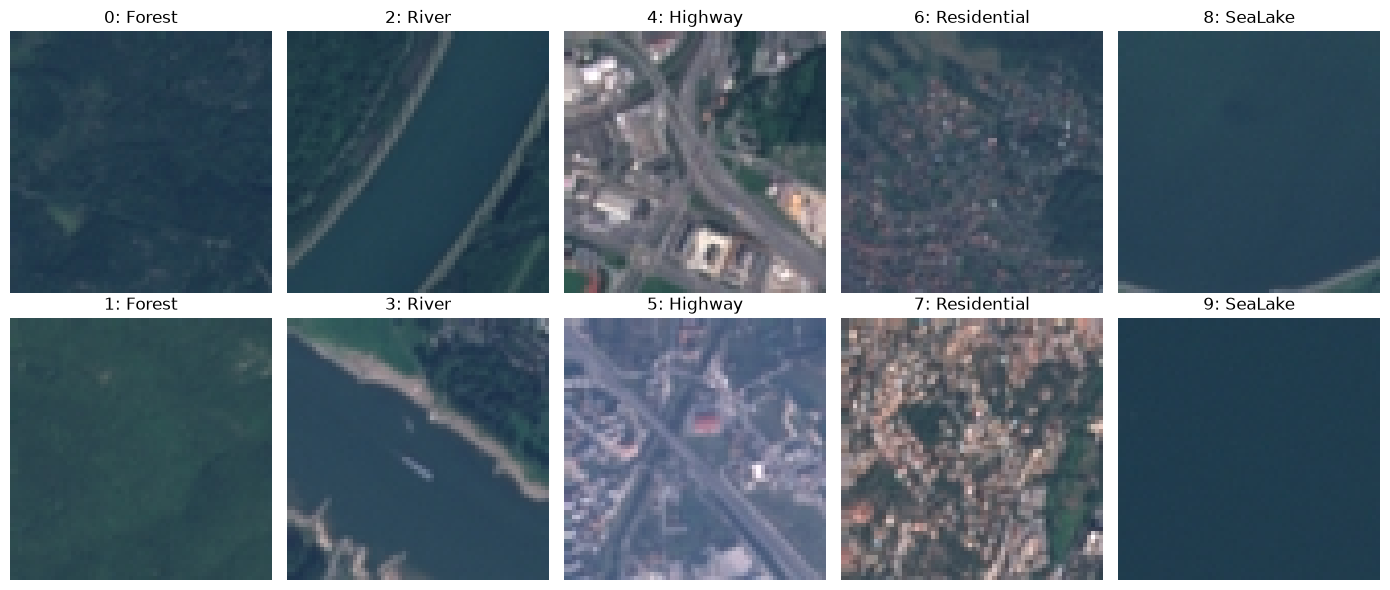

In [20]:
from PIL import Image
from transformers import AutoImageProcessor, AutoModel

root = '../lab3/data/eurosat/2750'
chosen = ['Forest', 'River', 'Highway', 'Residential', 'SeaLake']
rng = random.Random(4)
files = []
for c in chosen:
    files += [(c, os.path.join(root, c, f)) for f in rng.sample(sorted(os.listdir(os.path.join(root, c))), 2)]
imgs = [Image.open(p).convert('RGB') for _, p in files]
names = [f'{i}: {c}' for i, (c, _) in enumerate(files)]

fig, ax = plt.subplots(2, 5, figsize=(14, 6))
for a, im, n in zip(ax.T.ravel(), imgs, names):
    a.imshow(im); a.set_title(n); a.axis('off')
plt.tight_layout(); plt.show()

In [21]:
proc = AutoImageProcessor.from_pretrained('facebook/dinov2-small')
dino = AutoModel.from_pretrained('facebook/dinov2-small').to(dev).eval()
with torch.no_grad():
    inp = proc(images=imgs, return_tensors='pt').to(dev)
    feats = dino(**inp).last_hidden_state[:, 0]          # CLS-токен
feats = F.normalize(feats, p=2, dim=1).cpu()            # L2-нормування
print('розмір ознак:', tuple(feats.shape), ' норми:', feats.norm(dim=1)[:3].numpy().round(3))

D = torch.cdist(feats, feats).numpy()                   # попарні евклідові відстані
iu = np.triu_indices(len(imgs), k=1)
near = (iu[0][D[iu].argmin()], iu[1][D[iu].argmin()])
far = (iu[0][D[iu].argmax()], iu[1][D[iu].argmax()])
print(f'найближча пара: {names[near[0]]} і {names[near[1]]}, відстань {D[near]:.3f}')
print(f'найвіддаленіша пара: {names[far[0]]} і {names[far[1]]}, відстань {D[far]:.3f}')

розмір ознак: (10, 384)  норми: [1. 1. 1.]
найближча пара: 0: Forest і 1: Forest, відстань 0.531
найвіддаленіша пара: 4: Highway і 9: SeaLake, відстань 1.316


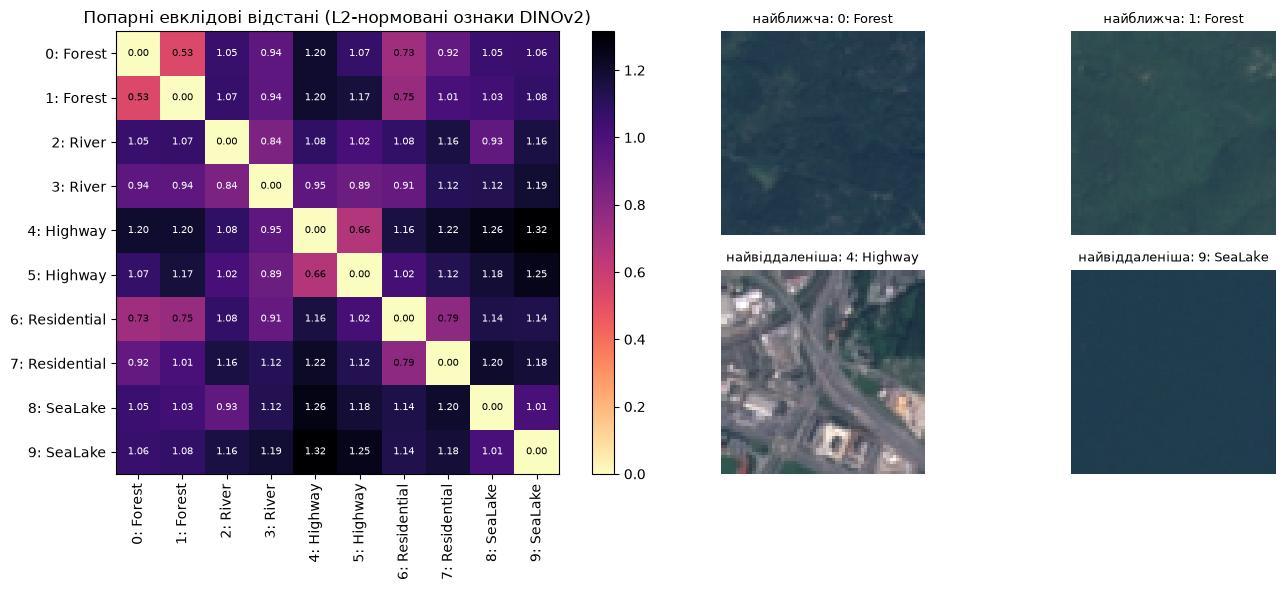

In [22]:
fig = plt.figure(figsize=(15, 6))
ax0 = fig.add_subplot(1, 2, 1)
im = ax0.imshow(D, cmap='magma_r')
ax0.set_xticks(range(10)); ax0.set_xticklabels(names, rotation=90); ax0.set_yticks(range(10)); ax0.set_yticklabels(names)
for i in range(10):
    for j in range(10):
        ax0.text(j, i, f'{D[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if D[i, j] > D.max() * 0.6 else 'black')
ax0.set_title('Попарні евклідові відстані (L2-нормовані ознаки DINOv2)'); fig.colorbar(im, ax=ax0, fraction=0.046)
for k, (pair, title) in enumerate([(near, 'найближча'), (far, 'найвіддаленіша')]):
    for m, idx in enumerate(pair):
        a = fig.add_subplot(2, 4, 3 + m + 4 * k)
        a.imshow(imgs[idx]); a.axis('off'); a.set_title(f'{title}: {names[idx]}', fontsize=9)
plt.tight_layout(); plt.show()

Вектори DINOv2 (384 числа) після L2-нормування мають довжину 1, тому евклідова відстань між ними лежить в межах [0, 2] і однозначно повʼязана з косинусною схожістю: d² = 2 − 2·cos.

- **Найближча пара:** два знімки лісу (0 і 1), відстань **0.53**. Це повністю узгоджується з візуальним сприйняттям: обидва темно-зелені однорідні текстури без обʼєктів.
- **Найвіддаленіша пара:** шосе (4) і озеро (9), відстань **1.32**. Теж логічно: на шосе багато ліній, будівель і контрастних деталей, а озеро є майже рівномірною темно-синьою площиною.
- Знімки одного класу здебільшого ближчі між собою: Highway-Highway 0.66, Residential-Residential 0.79, River-River 0.84. Виняток SeaLake-SeaLake (1.01): одне озеро темне й однорідне, на іншому видно берег, тож вони візуально справді різні. Ліс близький до житлової забудови (0.73), бо в EuroSAT житлові квартали часто зелені.

Тобто DINOv2 без жодних міток і без донавчання на супутникових знімках знаходить смислову схожість зображень, і її відстані збігаються з тим, як оцінює людина.

## Висновки

1. **Трансформер з нуля.** Реалізував encoder–decoder трансформер (multi-head attention, позиційне кодування, маски, розклад lr з warmup) і навчив його перекладати з англійської на українську на 155 тис. пар речень Tatoeba. BLEU на тесті 46.2, модель сама навчилась вирівнювати слова (видно по cross-attention). Основне обмеження: словник на рівні слів, через що рідкісні слова стають `<unk>`.
2. **Hugging Face pipeline.** Готові багатомовні моделі виконують zero-shot класифікацію (0.987 для правильного класу), абстрактивне резюме та переклад українською без жодного навчання. Порівняння з opus-mt показало, що велика модель не завжди краща: на «своєму» домені мій трансформер дав 47.4 проти 46.1 BLEU, а opus-mt іноді перекладає російською.
3. **Fine-tuning.** DistilRoBERTa після 2 епох дала accuracy 0.975 на AG News проти 0.955 у TF-IDF + NB (лаба 2) і 0.956 у LSTM + GloVe (лаба 3): помилок майже вдвічі менше.
4. **Diffusers.** sd-turbo генерує зображення за текстом за 1-4 кроки; композиція формується вже на першому кроці.
5. **DINOv2.** Ознаки self-supervised моделі добре відображають візуальну схожість: найближча пара - два ліси (0.53), найвіддаленіша - шосе й озеро (1.32), знімки одного класу здебільшого ближчі між собою.